# HEXACO scores from triplets with TIRT

Fit Thurstonian IRT to comparisons derived from best–worst choices
and examine the measurement parameters and trait scores.

## Model the comparisons

Let $p$ index respondents, $b$ index blocks, and $j,k$ name the first and
second statements in a comparison row. Write $\theta_{p,t(j)}$ for respondent $p$'s score on
the trait measured by statement $j$. The statement's expected utility is

$$
m_{pj}=q_j a_j\theta_{p,t(j)}+\nu_j.
$$

The positive loading $a_j$ measures how strongly the trait changes the
utility. The keying sign $q_j\in\{-1,+1\}$ sets the direction. The statement
effect $\nu_j$ shifts the utility by the same amount for all respondents.
Its prior is $\nu_j\mid v_j\sim\mathcal N(0,v_j)$, where $v_j$ is the
statement residual variance.

The binary response $Y_{pbjk}$ is 1 when $p$ prefers the first statement $j$
and 0 when $p$ prefers $k$. The default probit model gives

$$
P(Y_{pbjk}=1)=
\Phi\!\left(
\frac{q_j a_j\theta_{p,t(j)}-q_k a_k\theta_{p,t(k)}
      +\nu_j-\nu_k-\gamma_{bjk}}
     {\sqrt{v_j+v_k}}
\right).
$$

The numerator is the difference $m_{pj}-m_{pk}$ after subtracting the
pair threshold $\gamma_{bjk}$. The denominator is the residual SD of the
difference. The variances $v_j$ and $v_k$ add because the two statement
residuals in a comparison are independent. The standard normal cumulative
distribution function $\Phi$ turns the standardized difference into a
probability. At $m_{pj}-m_{pk}=\gamma_{bjk}$, either answer has probability $1/2$.

A triplet order $A>B>C$ supplies three comparison rows: $A>B$, $A>C$ and
$B>C$. The likelihood multiplies their Bernoulli probabilities conditional
on the traits and model parameters. The [joint-ranking example](tirt_rank_workflow.ipynb)
models the full order as one event. [TIRT model and priors](../models/tirt.md)

### Set the score scale

Trait means are zero and trait SDs are one. The design fixes loading direction,
and one residual variance per triplet is fixed at 0.5. These references give the
estimated scores and comparison parameters a scale. The workflow uses the
default probit link and priors.

## Read the questionnaire and responses

The bundled FC3 data contain HEXACO responses from [Li et al. (2025)](https://doi.org/10.1177/10944281241229784).
Use the same random sample of 120 respondents and all 20 triplets in
the TIRT and TIRTRank examples. The design gives each statement's trait
and keying. A keying value of −1 means higher trait scores lower the
statement's expected appeal.

In [1]:
import pandas as pd
import seaborn as sns

import pyfcirt as fc

sns.set_theme(style="ticks")

example = fc.load_example(
    "hexaco_fc3",
    model="TIRT",
    n_persons=120,
    random_seed=42,
)
example.data.design.head(3)

,block_id,position,statement_id,trait,keying
0,B1,1,i1,honestyhumility,-1
1,B1,2,i2,openness,-1
2,B1,3,i3,agreeableness,-1


Each row gives one person's answer to one triplet. In a response such as
`[3, None, 1]`, position 3 is most preferred and position 1 least preferred.
The middle position follows from these choices. TIRT derives the three
pairwise comparisons before fitting.

In [2]:
responses = example.data.responses.frame
responses.head(3)

,person_id,block_id,response
0,1,B1,"[3, None, 1]"
1,1,B2,"[3, None, 2]"
2,1,B3,"[1, None, 2]"


In [3]:
model = fc.Model()
model.add_fc(
    example.data.design,
    example.data.responses.frame,
    format="block_long",
    model="TIRT",
    response_format="mole",
)
model.prepare()
model.data_summary()

,n_blocks,size,n_persons,n_answered,n_missing
model_response_format,,,,,
TIRT / mole,20,3,120,2400,0


The dataset has 2,400 person–block responses. Each triplet contributes
three comparisons, for 7,200 comparisons altogether. In block B1, 34
of 120 respondents prefer i1 over i2.

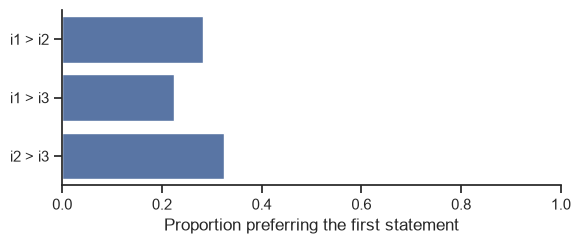

In [4]:
import matplotlib.pyplot as plt

observed = fc.response_summary(model.response_data(blocks=["B1"]))
first_preferred = observed.loc[observed.category.eq(1)]
chart = sns.catplot(
    data=first_preferred,
    kind="bar",
    x="proportion",
    y="pair_label",
    errorbar=None,
    height=2.6,
    aspect=2.3,
)
chart.set(
    xlim=(0, 1),
    xlabel="Proportion preferring the first statement",
    ylabel="",
)
plt.show()

## Fit the model

Fit four chains with 1,800 warmup iterations and 1,200 retained draws
per chain. The default sampler is BlackJAX.

In [5]:
model.fit(draws=1200, tune=1800, chains=4);

## Diagnose the chains

R-hat measures agreement between chains. Effective sample size (ESS)
indicates how much independent information their draws provide.
Check both before interpreting the parameter estimates.

In [6]:
import arviz as az
import numpy as np

posterior = model.idata.posterior.to_dataset().reset_coords(drop=True)
with np.errstate(invalid="ignore", divide="ignore"):
    r_hat = az.rhat(posterior).max().to_array().max().item()
    bulk = az.ess(posterior, method="bulk").min().to_array().min().item()
    tail = az.ess(posterior, method="tail").min().to_array().min().item()

print(f"Max R-hat: {r_hat:.3f}")
print(f"Min bulk / tail ESS: {bulk:.0f} / {tail:.0f}")
print("Divergences:", int(model.idata.sample_stats.diverging.sum()))

Max R-hat: 1.006
Min bulk / tail ESS: 1097 / 1710
Divergences: 0


The density and rank panels compare chains for one person's
Honesty–Humility and Openness scores.

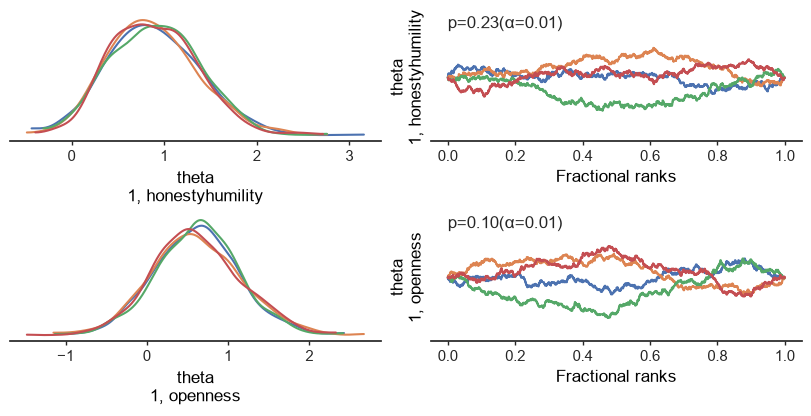

In [7]:
import arviz_plots as azp

azp.plot_rank_dist(
    model.idata,
    var_names=["theta"],
    coords={
        "person": [int(model.idata.posterior.person.values[0])],
        "trait": ["honestyhumility", "openness"],
    },
    compact=False,
    backend="matplotlib",
    figure_kwargs={"figsize": (8, 4), "layout": "constrained"},
)
plt.show()

## Read the measurement estimates

In B1, `loading` measures sensitivity to the trait, `residual_variance`
measures unexplained statement-level variation, and `cutpoint` is
the threshold for the labeled comparison.

In [8]:
model.coef(blocks=["B1"], kind="stats", round_to=2)

mean    sd  \
unit statement trait           pair    position parameter                       
B1   i1        honestyhumility nan     NaN      loading            1.46  0.37   
     i2        openness        nan     NaN      loading            0.60  0.18   
     i3        agreeableness   nan     NaN      loading            0.55  0.18   
     i1        honestyhumility nan     NaN      residual_variance  0.50   NaN   
     i2        openness        nan     NaN      residual_variance  1.13  0.59   
     i3        agreeableness   nan     NaN      residual_variance  1.37  0.62   
     nan       nan             i1 > i2 1        cutpoint           0.45  0.70   
                               i1 > i3 1        cutpoint           0.30  0.69   
                               i2 > i3 1        cutpoint           0.25  0.74   

                                                                   hdi95_lb  \
unit statement trait           pair    position parameter                     
B1   i1        honestyhumility nan     NaN      loading                0.79   
     i2        openness        nan     NaN      loading                0.27   
     i3        agreeableness   nan     NaN      loading                0.21   
     i1        honestyhumility nan     NaN      residual_variance       NaN   
     i2        openness        nan     NaN      residual_variance      0.02   
     i3        agreeableness   nan     NaN      residual_variance      0.31   
     nan       nan             i1 > i2 1        cutpoint              -1.00   
                               i1 > i3 1        cutpoint              -1.02   
                               i2 > i3 1        cutpoint              -1.16   

                                                                   hdi95_ub  
unit statement trait           pair    position parameter                    
B1   i1        honestyhumility nan     NaN      loading                2.18  
     i2        openness        nan     NaN      loading                0.98  
     i3        agreeableness   nan     NaN      loading                0.89  
     i1        honestyhumility nan     NaN      residual_variance       NaN  
     i2        openness        nan     NaN      residual_variance      2.22  
     i3        agreeableness   nan     NaN      residual_variance      2.68  
     nan       nan             i1 > i2 1        cutpoint               1.74  
                               i1 > i3 1        cutpoint               1.64  
                               i2 > i3 1        cutpoint               1.73

## Check response predictions

Compare predicted probabilities with observed preferences for i1 over i2
in B1. The diagonal marks agreement. The step curve estimates observed
preference frequency, and the band shows variation expected for replicated data.

In [9]:
predictions = model.posterior_predictive(draws=200, random_seed=45)

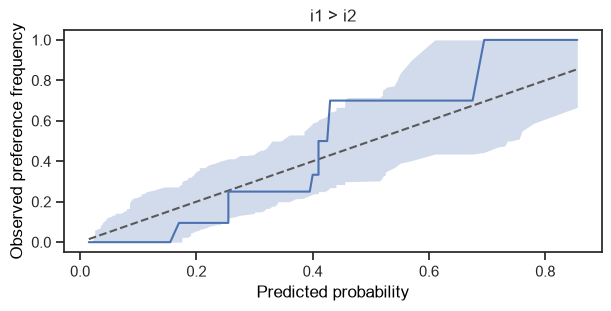

In [10]:
view = fc.predictive_view(predictions, block="B1")
design = model.idata["design"]

# Find the two statement labels for each pair, then the rows for this pair.
first = design.statement_label.isel(statement=design.pair_statement_1)
second = design.statement_label.isel(statement=design.pair_statement_2)
pair = design.pair.where((first == "i1") & (second == "i2"), drop=True)
pair_obs = design.obs.where(design.obs_pair == pair.item(), drop=True)

# Compare observed frequencies with predictions for the same rows.
azp.plot_ppc_pava(
    view.sel(obs=pair_obs),
    data_type="binary",
    backend="matplotlib",
    figure_kwargs={"figsize": (6, 3), "layout": "constrained"},
)
plt.gca().set(
    title="i1 > i2",
    xlabel="Predicted probability",
    ylabel="Observed preference frequency",
)
plt.show()

### Check overall fit

The Pearson check compares a discrepancy for observed and replicated
comparisons. The posterior predictive p-value (PPP) is the share of
replicates with a discrepancy at least as large as the observed one.

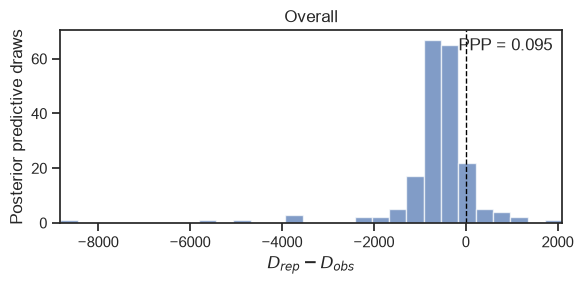

In [11]:
overall = model.chi_ppp(predictions=predictions)
fc.plot_ppp(overall, quantile_range=(0.005, 0.995), figsize=(6, 3))
plt.show()

The same check can be calculated for each comparison in B1.
Each row uses only the answers for that pair.

In [12]:
pair_checks = model.chi_ppp(
    predictions=predictions,
    blocks=["B1"],
    groupby="pair",
    store=False,
)
pair_table = pair_checks[["PPP", "n_obs"]].to_dataframe()
pair_table.set_index(["statement_1", "statement_2"]).round({"PPP": 3})

PPP  n_obs  unit
statement_1 statement_2                    
i1          i2           0.495    120     0
            i3           0.280    120     0
i2          i3           0.230    120     0

## Read score precision

The plot shows how sharply the likelihood distinguishes nearby
Honesty–Humility and Openness scores at the posterior mean item
parameters. Each dot represents one respondent.

In [13]:
info = model.information(progressbar=False)

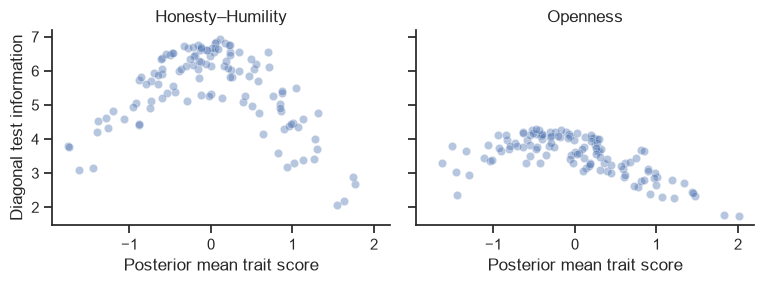

In [14]:
scores = model.idata.posterior.theta.mean(("chain", "draw"))
traits = {"honestyhumility": "Honesty–Humility", "openness": "Openness"}
frames = [
    pd.DataFrame(
        {
            "Score": scores.sel(trait=trait).values,
            "Information": info.test_information.sel(trait=trait, trait_aux=trait).values,
            "Trait": label,
        }
    )
    for trait, label in traits.items()
]
chart = sns.relplot(
    data=pd.concat(frames),
    x="Score",
    y="Information",
    col="Trait",
    height=3,
    aspect=1.3,
    alpha=0.4,
)
chart.set_axis_labels("Posterior mean trait score", "Diagonal test information")
chart.set_titles("{col_name}")
plt.show()

Empirical reliability compares variation in scores across respondents
with their posterior uncertainty. It is reported for each trait.

In [15]:
model.reliability()["reliability"].to_series().round(3).to_frame("Reliability")

,Reliability
trait,
honestyhumility,0.738
openness,0.664
agreeableness,0.601
emotionality,0.678
conscientiousness,0.697
extraversion,0.771


The ridges show the posterior scores of the first three respondents.
The markers show posterior means and the lines show 50% and 95% HDIs.

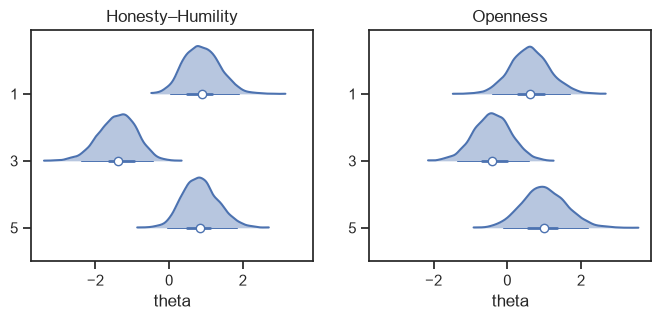

In [16]:
fc.plot_ridge(
    model.idata,
    coords={
        "person": model.idata.posterior.person.values[:3].tolist(),
        "trait": list(traits),
    },
    max_rows=3,
    col_wrap=2,
    figsize=(8, 3),
)
for ax, trait in zip(plt.gcf().axes, traits, strict=False):
    ax.set_title(traits[trait])
plt.show()

See [statement response curves](statement_curves.ipynb) to visualize how the
estimated parameters change a statement's appeal across trait scores.